<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS11/Praktikum2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Langkah 1 - Ilustrasi Data Non-Linier

In [8]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

In [9]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

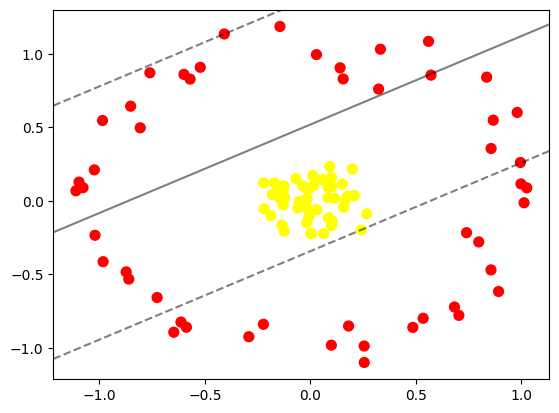

In [10]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

In [11]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

r = np.exp(-(X ** 2).sum(1))

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-0.58742574, -0.86061265],
       [-0.98539738,  0.54640529],
       [ 0.32414484,  0.76047476],
       [-0.13443114, -0.16379814],
       [ 0.74109454, -0.21721454],
       [-0.98256937, -0.41458242],
       [-0.86077431, -0.53304895],
       [ 0.89306649, -0.61740646],
       [ 0.57270274,  0.85524081],
       [-0.12880472, -0.02779594],
       [-0.64725398, -0.89466808],
       [ 0.10133398, -0.16842299],
       [ 0.01707983,  0.10446405],
       [-0.80649316,  0.49669463],
       [ 0.02927468,  0.99500911],
       [ 0.08521669,  0.09340671],
       [-1.09676218,  0.12739428],
       [ 0.10095249,  0.16018838],
       [-0.56984782,  0.82822854],
       [ 0.1036686 , -0.13818268],
       [-0.01353231,  0.07674376],
       [-0.01310675, -0.05262101],
       [ 0.25605396, -1.1005543 ],
       [-0.40782817,  1.13532247],
       [-0.18018575,  0.04344865],
       [ 0.20733962,  0.03260519],
       [-0.01529426,  0.01332526],
       [ 0.33275776,  1.031921  ],
       [ 0.15283307,  0.11231377],
       [-0.06816224,  0.15126447],
       [-1.11158108,  0.06796308],
       [ 0.25570034, -0.98834469],
       [ 0.00240056, -0.22265609],
       [-0.6133577 , -0.8255326 ],
       [-0.14359967,  0.01549487],
       [-0.59921969,  0.86030199],
       [ 0.01179822,  0.17383863],
       [ 0.17725701,  0.02998443],
       [ 0.15612683,  0.82953467],
       [ 0.00721553, -0.22304826],
       [-0.0167241 , -0.14890126],
       [ 1.01401557, -0.01344681],
       [-0.85188148,  0.6438643 ],
       [ 0.26755395, -0.08815333],
       [-1.07780659,  0.0891157 ],
       [ 0.1675887 ,  0.009694  ],
       [ 0.10237755,  0.09541764],
       [ 0.06325932, -0.22369741],
       [-0.00430307,  0.08310422],
       [ 0.70469707, -0.77987743],
       [ 0.05712372,  0.14493905],
       [-0.12174773,  0.02220354],
       [ 0.19984212,  0.21590736],
       [ 0.09051195, -0.11643   ],
       [ 0.99660489,  0.26080257],
       [-0.52173169,  0.90867315],
       [-0.00535048, -0.10874154],
       [ 0.48642529, -0.86185205],
       [-1.02098033, -0.23461124],
       [ 0.86787106,  0.54868424],
       [ 0.79908219, -0.28002212],
       [-0.05162463, -0.00518425],
       [-0.12388713, -0.20715705],
       [-0.13914881,  0.01543851],
       [-1.0241404 ,  0.21036252],
       [ 0.15886732, -0.04380832],
       [ 0.1817261 , -0.85225687],
       [ 0.09994547, -0.98280404],
       [ 0.141433  ,  0.90497369],
       [-0.16967476,  0.12222778],
       [ 0.85761247,  0.35592902],
       [ 0.56093112,  1.08521319],
       [ 0.8366698 ,  0.84132734],
       [-0.22221196, -0.84064571],
       [-0.22087121,  0.12197224],
       [ 0.53540414, -0.79975738],
       [ 0.9991948 ,  0.11470346],
       [ 0.2419529 , -0.19762877],
       [ 1.02693749,  0.08805393],
       [ 0.20973539,  0.0353654 ],
       [ 0.03109592, -0.05998912],
       [ 0.08595547, -0.11816979],
       [ 0.09198681,  0.23356796],
       [ 0.68376113, -0.72285467],
       [ 0.08379784,  0.02119139],
       [ 0.11646293,  0.01620887],
       [-0.87310063, -0.48399754],
       [ 0.98141825,  0.60118885],
       [ 0.85721154, -0.47036422],
       [-0.0593811 , -0.04917882],
       [-0.03505656,  0.10047883],
       [-0.15620762,  0.07609243],
       [-0.76078076,  0.87095507],
       [-0.21856468, -0.05413876],
       [-0.14398416,  1.18640153],
       [-0.12518647,  0.10114052],
       [-0.18606339, -0.10094647],
       [-0.29143672, -0.92533462],
       [-0.12865501,  0.06698002],
       [-0.72623024, -0.65855994]]), y=array([0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0,
       0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0]))>

Langkah 2 - Fitting Model

In [12]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

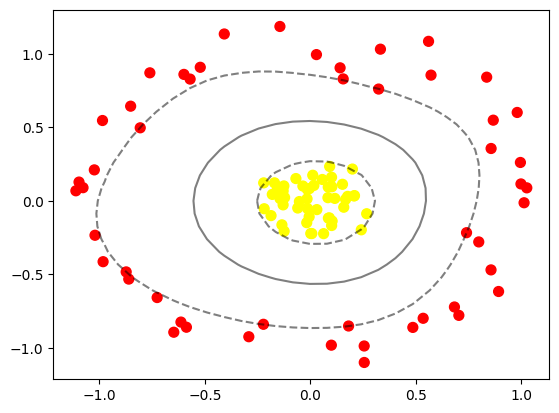

In [13]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')